# L0: efecto de los parámetros del residual

¿Qué tan sensible es la wPINN con residual **L0** (desigualdad de entropía de
Kruzhkov, ec. 10 del paper) a las perillas que hay dentro del residual? Se
estudia sobre la **rarefacción** (ec. 17), el caso donde L0 tiene que elegir
entre el abanico de entropía y el choque de expansión.

**Cómo leer este notebook**

- **Parte 1 — Biblioteca.** Las definiciones (red, problema, residual, bucle
  min-max, métricas). Son las de `wpinns_L0.ipynb`, recortadas a lo que L0 usa.
  **Se puede ejecutar sin leer.**
- **Parte 2 — Experimentos.** Lo importante. Una celda de entrenamiento donde
  se ve **todo** lo que entra (el problema, el caso base y los valores a
  barrer), y después una sección por parámetro.

**Parámetros que se barren** (uno a la vez; el resto queda en el caso base del paper)

| Parámetro | Valores | Caso base | Qué controla |
|---|---|---|---|
| `seed` | 0, 1, 2 | 0 | nada: mide el ruido entre corridas |
| `n_kruzhkov_constants` | 3, 9, 17 | 9 | cuántas constantes $c$ se prueban |
| `kruzhkov_margin_fraction` | 0, 0.25, 0.5 | 0.25 | cuánto salen las $c$ del rango de $u$ |
| `aggregation_mode` | max, mean | max | cómo se juntan los $J(c)$ en un escalar |
| `n_adversary_steps` | 1, 5, 20 | 5 | pasos de ascenso de $\varphi$ por época |
| `adversary_learning_rate` | 1e-3, 1e-2, 1e-1 | 1e-2 | tamaño del paso de $\varphi$ |
| `reset_adversary_every_n_epochs` | 1, 10, nunca | 1 | cada cuánto se resortea $\varphi$ |

# Parte 1 — Biblioteca

## Inicialización
Precisión `float32`, dispositivo y semillas.

In [1]:
import math
import time
from dataclasses import dataclass          # se usa en la celda 3 para describir cada problema
from typing import Callable, Optional      # idem: tipos de los campos del problema

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Precision por defecto de TODO tensor que creemos sin especificar dtype.
# float32 y no float64 porque:
#   (a) en 2D el costo lo domina el numero de puntos de colocacion, no el redondeo;
#   (b) en GPUs Blackwell (RTX 50xx) la doble precision esta castigada en hardware,
#       del orden de decenas de veces mas lenta que la simple.
# Si mas adelante el residual debil muestra ruido numerico inexplicable, subir a float64
# es el primer experimento a hacer.
torch.set_default_dtype(torch.float32)

# Dispositivo unico para todo el notebook. Se resuelve UNA vez y se reutiliza.
# Si se deja implicito terminamos con tensores en CPU y red en GPU, y torch aborta
# el entrenamiento con un error de dispositivo a mitad de camino.
COMPUTE_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_random_seed(seed: int = 0) -> None:
    """Fix every random source so a training run can be reproduced exactly.

    Two independent generators are in play: numpy drives anything we do with
    arrays outside the graph, torch drives weight initialisation and the
    Monte-Carlo sampling of collocation points.
    """
    # numpy: lo usamos poco, pero basta un np.random.rand en una grafica para
    # que dos corridas "identicas" dejen de serlo.
    np.random.seed(seed)
    # torch: cubre la inicializacion de pesos Y el muestreo de puntos, que es
    # la fuente de varianza mas fuerte en wPINN (rarefaccion vario entre 0.07 y 0.33
    # entre semillas en los experimentos 1D).
    torch.manual_seed(seed)


# Verificacion de entorno: debe decir algo como "2.14.0+cu128 cuda".
# Si dice "+cpu" la build de torch no trae kernels CUDA y hay que reinstalarla.
print(torch.__version__, COMPUTE_DEVICE)

2.11.0+cu128 cuda


## Perceptrón multicapa
El mismo bloque sirve de red solución $u_\theta$ y de red test $\varphi_\eta$.

In [2]:
from typing import Sequence   # anchos de capa y cotas: listas o tuplas


class MLP(nn.Module):
    """Multi-layer perceptron: a fully connected feed-forward network R^n -> R^m.

    Deliberately problem-agnostic so it can be reused as a base block for any
    scientific machine learning task. Nothing in here knows about PDEs, space,
    time, or the number of coordinates. In this notebook it plays two roles:
    the solution network u_theta(x, y, t) and the adversarial test network
    phi_eta(x, y, t); only the constructor arguments change between the two.

    Parameters
    ----------
    n_input_features    : dimension of the input vector (3 for (x, y, t)).
    n_output_features   : dimension of the output vector (1 for a scalar law).
    hidden_layer_widths : neurons per hidden layer, one entry per layer
                          (paper: [20] * 6 for u, [10] * 4 for phi).
    activation          : activation module class placed after every hidden
                          layer. Default nn.Tanh, the usual choice for PINNs.
    input_lower_bounds  : optional, one value per input feature. Together with
                          input_upper_bounds rescales inputs to [-1, 1] before
                          the first layer. None disables the rescaling.
    input_upper_bounds  : see input_lower_bounds.
    weight_initialiser  : in-place initialiser applied to every linear layer's
                          weight matrix. Default Glorot / Xavier normal.
    """

    def __init__(
        self,
        n_input_features: int,
        n_output_features: int,
        hidden_layer_widths: Sequence[int],
        activation: type[nn.Module] = nn.Tanh,
        input_lower_bounds: Optional[Sequence[float]] = None,
        input_upper_bounds: Optional[Sequence[float]] = None,
        weight_initialiser: Callable[[torch.Tensor], torch.Tensor] = nn.init.xavier_normal_,
    ) -> None:
        super().__init__()

        # Las cotas son opcionales para que la clase sirva en problemas donde la
        # entrada ya viene normalizada. Se exige que vengan las dos o ninguna:
        # una sola no define un reescalamiento.
        if (input_lower_bounds is None) != (input_upper_bounds is None):
            raise ValueError("input_lower_bounds and input_upper_bounds must be given together")
        if input_lower_bounds is not None and len(input_lower_bounds) != n_input_features:
            raise ValueError("bounds must have one entry per input feature")

        # Cotas guardadas como buffers y NO como parámetros: viajan con la red a la
        # GPU (model.to(device)) y se guardan con state_dict, pero el optimizador
        # no las toca porque no son entrenables. register_buffer acepta None, así
        # que el atributo existe siempre y forward sólo pregunta si es None.
        self.register_buffer(
            "input_lower_bounds",
            None if input_lower_bounds is None else torch.tensor(input_lower_bounds),
        )
        self.register_buffer(
            "input_upper_bounds",
            None if input_upper_bounds is None else torch.tensor(input_upper_bounds),
        )

        # Se arma la lista [Linear, act, Linear, act, ..., Linear] recorriendo los
        # anchos de capa. Con una lista de anchos en vez de (ancho, n_capas) la
        # misma clase admite redes no uniformes, como una que se estrecha hacia
        # la salida, sin cambiar una línea.
        layer_input_widths = [n_input_features, *hidden_layer_widths]
        layers: list[nn.Module] = []
        for input_width, output_width in zip(layer_input_widths[:-1], layer_input_widths[1:]):
            layers += [nn.Linear(input_width, output_width), activation()]
        
        # Última capa sin activación: la salida puede tomar cualquier valor real
        # (por ejemplo -1 en la rarefacción); tanh la recortaría a (-1, 1).
        layers.append(nn.Linear(layer_input_widths[-1], n_output_features))
        self.network = nn.Sequential(*layers)

        # Inicialización de pesos. Por defecto Glorot (Xavier), que es la pensada
        # para tanh: mantiene la varianza de las activaciones de capa en capa, así
        # la red no arranca ni saturada (gradiente cero) ni colapsada en cero. La
        # de PyTorch por defecto (Kaiming uniforme con a=sqrt(5)) está pensada
        # para ReLU. Si alguien pasa activation=nn.ReLU debería pasar también
        # weight_initialiser=nn.init.kaiming_normal_; por eso es argumento.
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                weight_initialiser(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, input_points: torch.Tensor) -> torch.Tensor:
        """Evaluate the network on a batch of inputs.

        Parameters
        ----------
        input_points : tensor of shape (n_points, n_input_features).

        Returns
        -------
        tensor of shape (n_points, n_output_features).
        """
        # Reescalamiento afín de cada coordenada al intervalo [-1, 1] antes de la
        # primera capa, sólo si se dieron cotas. Sin esto, la rarefacción
        # (x en [-5.5, 5.5], t en [0, 2.5]) mete valores de magnitud 5 en tanh y
        # satura la primera capa desde la época cero. Con las cotas dentro de la
        # red, el resto del notebook trabaja en coordenadas físicas y nunca tiene
        # que acordarse de escalar.
        if self.input_lower_bounds is not None:
            input_points = (
                2.0 * (input_points - self.input_lower_bounds)
                / (self.input_upper_bounds - self.input_lower_bounds)
                - 1.0
            )
        return self.network(input_points)


def count_trainable_parameters(model: nn.Module) -> int:
    """Total number of scalar weights the optimiser will update."""
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

## El problema como dato
Flujos, dominio, $T$, dato inicial, frontera, exacta y rango de $u$ en un solo objeto.

In [3]:
# Aliases de tipo. Todos los campos reciben tensores por lotes y devuelven
# (n_points, 1), para poder restarlos de la salida de la red sin reshape.
#   FluxFunction : H_i(u), recibe u de forma (n_points, 1).
#   InitialField : u_0(spatial_points), recibe (n_points, n_spatial_dimensions).
#   SpaceTimeField : u(spatial_points, time), recibe además time de forma (n_points, 1).
FluxFunction = Callable[[torch.Tensor], torch.Tensor]
InitialField = Callable[[torch.Tensor], torch.Tensor]
SpaceTimeField = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


@dataclass(frozen=True)
class ConservationLawProblem:
    """One instance of the scalar conservation law u_t + sum_i d/dx_i H_i(u) = 0
    on a box in R^d, for any number d of spatial dimensions.

    Nothing in the class assumes d = 2: the dimension is read from the length
    of the bounds, and every field receives the spatial coordinates as one
    tensor of shape (n_points, d) instead of separate x, y arguments. The four
    cases of the paper are d = 2 instances.

    Attributes
    ----------
    name                    : label used in plots and logs.
    fluxes                  : (H_1, ..., H_d), one flux per spatial direction.
    flux_derivatives        : (H_1', ..., H_d'), needed by the strong residual
                              u_t + sum_i H_i'(u) du/dx_i.
    spatial_lower_bounds    : (x_1_min, ..., x_d_min).
    spatial_upper_bounds    : (x_1_max, ..., x_d_max).
    final_time              : T, the time horizon; time runs over [0, T].
    initial_condition       : u_0(spatial_points).
    boundary_condition      : g(spatial_points, time) on the spatial boundary.
                              None when boundary_condition_type is "periodic".
    boundary_condition_type : "dirichlet" or "periodic", applied to every face.
    exact_solution          : u(spatial_points, time) when known, else None.
    solution_value_range    : (u_min, u_max) attained by the solution. Fixes
                              the colour scale of every plot and the range of
                              the Kruzhkov constants c in the wPINN.
    """

    name: str
    fluxes: tuple[FluxFunction, ...]
    flux_derivatives: tuple[FluxFunction, ...]
    spatial_lower_bounds: tuple[float, ...]
    spatial_upper_bounds: tuple[float, ...]
    final_time: float
    initial_condition: InitialField
    boundary_condition: Optional[SpaceTimeField]
    boundary_condition_type: str
    exact_solution: Optional[SpaceTimeField]
    solution_value_range: tuple[float, float]

    def __post_init__(self) -> None:
        # Se valida en construcción y no al usar, para que un error de dimensión
        # explote aquí con un mensaje claro y no dentro de autograd.
        n_dimensions = len(self.spatial_lower_bounds)
        if len(self.spatial_upper_bounds) != n_dimensions:
            raise ValueError("spatial_lower_bounds and spatial_upper_bounds must have the same length")
        if len(self.fluxes) != n_dimensions or len(self.flux_derivatives) != n_dimensions:
            raise ValueError("one flux and one flux derivative are needed per spatial dimension")
        if self.boundary_condition_type not in ("dirichlet", "periodic"):
            raise ValueError(f"unknown boundary_condition_type {self.boundary_condition_type!r}")
        if (self.boundary_condition is None) != (self.boundary_condition_type == "periodic"):
            raise ValueError("boundary_condition must be None exactly when the boundary is periodic")

    @property
    def n_spatial_dimensions(self) -> int:
        return len(self.spatial_lower_bounds)

    # Las cotas espacio-temporales (x_1, ..., x_d, t) son exactamente lo que pide
    # el MLP de la celda 2, así que se exponen como propiedades para no
    # reconstruir la tupla a mano cada vez que se crea una red.
    @property
    def space_time_lower_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_lower_bounds, 0.0)

    @property
    def space_time_upper_bounds(self) -> tuple[float, ...]:
        return (*self.spatial_upper_bounds, self.final_time)

## Flujo de Burgers

In [4]:
# --- Flujos ---------------------------------------------------------------
# Se definen como funciones con nombre y no como lambdas porque aparecen en los
# reprs y en los mensajes de error, y "burgers_flux" se lee mejor que "<lambda>".
def burgers_flux(u: torch.Tensor) -> torch.Tensor:
    """H(u) = u^2 / 2, the inviscid Burgers flux (paper eq. 16)."""
    return 0.5 * u**2


def burgers_flux_derivative(u: torch.Tensor) -> torch.Tensor:
    """H'(u) = u."""
    return u

## Dato inicial, frontera y exacta de la rarefacción
Las piezas con que la Parte 2 arma el `RAREFACTION_PROBLEM`.

In [5]:
# Columnas de la matriz de coordenadas. Nombrarlas evita el "0" y "1" mágicos
# en cada campo y deja claro que el paper trabaja con (x, y) en ese orden.
X_COLUMN = 0
Y_COLUMN = 1


def coordinate_column(spatial_points: torch.Tensor, column: int) -> torch.Tensor:
    """Extract one coordinate as a column tensor of shape (n_points, 1)."""
    # El slice column:column+1 y no [:, column] preserva la segunda dimensión,
    # así el resultado se opera directamente con salidas de red (n_points, 1).
    return spatial_points[:, column : column + 1]


# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_initial_condition(spatial_points: torch.Tensor) -> torch.Tensor:
    """u_0 = -1 for x <= 0, +1 for x > 0. Independent of y."""
    x = coordinate_column(spatial_points, X_COLUMN)
    return torch.where(x <= 0.0, -1.0, 1.0)

In [6]:
# --- Condición de frontera compartida por los tres casos de Burgers ---------
def initial_condition_frozen_in_time(initial_condition: InitialField) -> SpaceTimeField:
    """Build g(spatial_points, t) = u_0(spatial_points): the boundary keeps
    its initial value.

    Valid as long as no wave reaches the spatial boundary before T, which holds
    for the three Burgers cases: the rarefaction fan reaches |x| = 2.5 < 5.5,
    the shock reaches x = 0.25 < 1 and the 2D Riemann waves travel at most
    0.25 from (0.25, 0.25).
    """
    def boundary_condition(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
        return initial_condition(spatial_points)
    return boundary_condition

In [7]:
# --- Rarefacción (ec. 17) ---------------------------------------------------
def rarefaction_exact_solution(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Entropy solution: a fan u = x / t clipped to [-1, 1].

    Independent of y because the data is, so it is the 1D Burgers fan.
    """
    x = coordinate_column(spatial_points, X_COLUMN)
    # En t = 0 la división x / t es 0/0 o ±inf. Se protege con un t mínimo
    # positivo: para t < 1e-12, x / t queda fuera de [-1, 1] salvo en x = 0, así
    # que clamp devuelve ±1, que coincide con el dato inicial.
    safe_time = torch.clamp(time, min=1e-12)
    return torch.clamp(x / safe_time, min=-1.0, max=1.0)

## Espacio, tiempo y muestreo
El tiempo es siempre la última columna. Puntos Monte Carlo uniformes.

In [8]:
# Convención de todo el notebook: un punto espacio-temporal es una fila
# (x_1, ..., x_d, t) y el tiempo es SIEMPRE la última columna. Estas dos
# funciones son el único lugar donde se asume ese orden.
TIME_COLUMN = -1


def split_space_time(space_time_points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Split (n_points, d + 1) into spatial (n_points, d) and time (n_points, 1)."""
    return space_time_points[:, :TIME_COLUMN], space_time_points[:, TIME_COLUMN:]


def join_space_time(spatial_points: torch.Tensor, time: torch.Tensor) -> torch.Tensor:
    """Inverse of split_space_time: concatenate along the feature axis."""
    return torch.cat([spatial_points, time], dim=1)

In [9]:
def sample_uniform_in_box(
    lower_bounds: Sequence[float],
    upper_bounds: Sequence[float],
    n_points: int,
    device: torch.device = COMPUTE_DEVICE,
) -> torch.Tensor:
    """Draw n_points uniformly at random inside the box [lower, upper] in R^k.

    Returns a tensor of shape (n_points, k). Monte-Carlo sampling and not a
    grid because the PINN loss is an expectation over the domain, and uniform
    random points estimate it without the curse of dimensionality of a grid.
    """
    lower = torch.tensor(lower_bounds, device=device)
    upper = torch.tensor(upper_bounds, device=device)
    # torch.rand da U[0, 1); el mapa afín lo lleva a [lower, upper). Se genera
    # directamente en device para no pagar una copia CPU -> GPU por época.
    unit_samples = torch.rand(n_points, len(lower_bounds), device=device)
    return lower + (upper - lower) * unit_samples

In [10]:
def sample_interior_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points in the open space-time box, where the PDE residual is enforced."""
    return sample_uniform_in_box(problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points)


def sample_initial_points(problem: ConservationLawProblem, n_points: int) -> torch.Tensor:
    """Points on the slice t = 0, where u = u_0 is enforced."""
    spatial_points = sample_uniform_in_box(problem.spatial_lower_bounds, problem.spatial_upper_bounds, n_points)
    time_zero = torch.zeros(n_points, 1, device=spatial_points.device)
    return join_space_time(spatial_points, time_zero)


def sample_boundary_points(
    problem: ConservationLawProblem, n_points: int
) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
    """Points on the lateral boundary (spatial faces x [0, T]).

    Returns (boundary_points, periodic_partner_points). For a Dirichlet
    problem the partner is None. For a periodic problem the partner has the
    same shape as boundary_points and each row is the same point with the
    face coordinate moved to the opposite face, so that the loss can enforce
    u(boundary) = u(partner).
    """
    n_faces = 2 * problem.n_spatial_dimensions
    # Se reparte el presupuesto por igual entre las 2d caras. Si n_points no es
    # múltiplo de 2d se pierde el residuo; es irrelevante frente a miles de puntos.
    n_points_per_face = n_points // n_faces

    boundary_points_per_face = []
    partner_points_per_face = []
    for dimension in range(problem.n_spatial_dimensions):
        for face_bound, opposite_bound in (
            (problem.spatial_lower_bounds[dimension], problem.spatial_upper_bounds[dimension]),
            (problem.spatial_upper_bounds[dimension], problem.spatial_lower_bounds[dimension]),
        ):
            # Se muestrea en toda la caja espacio-temporal y luego se "aplasta"
            # la coordenada de la cara sobre su cota. Es más simple que
            # construir la caja (d-1)-dimensional de cada cara a mano y da la
            # misma distribución uniforme sobre la cara.
            face_points = sample_uniform_in_box(
                problem.space_time_lower_bounds, problem.space_time_upper_bounds, n_points_per_face
            )
            face_points[:, dimension] = face_bound
            boundary_points_per_face.append(face_points)

            # El compañero periódico comparte todas las coordenadas (incluido t)
            # y sólo cambia la coordenada de la cara por la cota opuesta.
            partner_points = face_points.clone()
            partner_points[:, dimension] = opposite_bound
            partner_points_per_face.append(partner_points)

    boundary_points = torch.cat(boundary_points_per_face, dim=0)
    if problem.boundary_condition_type == "periodic":
        return boundary_points, torch.cat(partner_points_per_face, dim=0)
    return boundary_points, None

In [11]:
@dataclass(frozen=True)
class CollocationPoints:
    """One Monte-Carlo draw of every point set the loss needs.

    All tensors have d + 1 columns (x_1, ..., x_d, t) and live on the compute
    device. periodic_partner_points is None for Dirichlet problems.
    """

    interior_points: torch.Tensor
    initial_points: torch.Tensor
    boundary_points: torch.Tensor
    periodic_partner_points: Optional[torch.Tensor]


def sample_collocation_points(
    problem: ConservationLawProblem,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
) -> CollocationPoints:
    """Draw a fresh set of interior, initial and boundary points for one problem."""
    boundary_points, periodic_partner_points = sample_boundary_points(problem, n_boundary_points)
    return CollocationPoints(
        interior_points=sample_interior_points(problem, n_interior_points),
        initial_points=sample_initial_points(problem, n_initial_points),
        boundary_points=boundary_points,
        periodic_partner_points=periodic_partner_points,
    )

## Derivadas por autograd

In [12]:
def gradient_with_respect_to_inputs(output: torch.Tensor, input_points: torch.Tensor) -> torch.Tensor:
    """d(output)/d(input) for a batch, returned with the shape of input_points.

    output has shape (n_points, 1) and input_points (n_points, k); the result
    is (n_points, k), column j being the partial derivative along input j.
    """
    # Truco estándar: la suma de las salidas tiene gradiente igual al jacobiano
    # fila a fila, porque cada salida depende SÓLO de su propia fila de entrada.
    # create_graph=True deja el grafo vivo para poder derivar otra vez (laplaciano)
    # y para que el gradiente de la pérdida atraviese este cálculo.
    return torch.autograd.grad(output.sum(), input_points, create_graph=True)[0]

## Términos de datos
Dato inicial y frontera, penalizados con error cuadrático medio.

In [13]:
from dataclasses import field, replace   # listas por defecto en la historia; copias del presupuesto

# Una "penalización" reduce un tensor de discrepancias puntuales (n_points, 1)
# a un escalar. Ninguna pérdida sabe cuál se usa: se le pasa como argumento,
# así que cambiar de L2 a L1 en los términos de datos es cambiar un argumento.
PenaltyFunction = Callable[[torch.Tensor], torch.Tensor]


def mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Mean of the squares: the Monte-Carlo estimate of the squared L2 norm."""
    return torch.mean(values**2)


def mean_absolute(values: torch.Tensor) -> torch.Tensor:
    """Mean of absolute values: the Monte-Carlo estimate of the L1 norm."""
    return torch.mean(values.abs())


def root_mean_squared(values: torch.Tensor) -> torch.Tensor:
    """Square root of mean_squared: same minimiser, gradients of different scale."""
    return torch.sqrt(mean_squared(values))

In [14]:
def data_loss_terms(
    network: nn.Module,
    problem: ConservationLawProblem,
    points: CollocationPoints,
    penalty: PenaltyFunction = mean_squared,
) -> dict[str, torch.Tensor]:
    """Initial and boundary mismatch penalties, keys "initial" and "boundary".

    Identical for the strong and the weak formulation: only the PDE term
    changes between them. strong_pinn_loss_terms could call this too.
    """
    initial_spatial_points, _ = split_space_time(points.initial_points)
    initial_mismatch = network(points.initial_points) - problem.initial_condition(initial_spatial_points)

    if problem.boundary_condition_type == "periodic":
        # Periódica: la red debe valer lo mismo en las dos caras opuestas.
        boundary_mismatch = network(points.boundary_points) - network(points.periodic_partner_points)
    else:
        boundary_spatial_points, boundary_time = split_space_time(points.boundary_points)
        boundary_mismatch = network(points.boundary_points) - problem.boundary_condition(boundary_spatial_points, boundary_time)

    return {"initial": penalty(initial_mismatch), "boundary": penalty(boundary_mismatch)}

## La función test adversaria
$\varphi = \text{ventana}(x)\cdot\text{softplus}(\xi(x,t))$: positiva (la
desigualdad de Kruzhkov se prueba contra $\varphi \ge 0$) y nula en la frontera
espacial.

In [15]:
import torch.nn.functional as functional   # softplus, una de las transformaciones de rango

# Dos "ganchos" definen la estructura de phi a partir del MLP interno xi:
#   phi(x, t) = window(x, t) * range_transform(xi(x, t))
# range_transform actúa sobre el VALOR (impone signo, cota, etc.);
# window actúa sobre el DOMINIO (dónde phi se anula). Cualquiera puede ser None.
# El paper no impone ninguno; De Ryck usa softplus + campana polinómica.
RangeTransform = Callable[[torch.Tensor], torch.Tensor]
WindowFunction = Callable[[torch.Tensor], torch.Tensor]


class TestFunctionNetwork(nn.Module):
    """Adversarial test function phi(x, t) of the weak formulation.

        phi(x, t) = window(x, t) * range_transform(xi(x, t))

    xi is a plain MLP (the paper: 4 layers of 10 neurons). range_transform
    shapes the values (e.g. softplus for phi > 0) and window shapes the
    support (e.g. a bump vanishing on the spatial boundary). None for both
    reproduces the paper literally. Any callable with the right signature
    can be plugged in, so alternative constraints are a one-line change.

    Parameters
    ----------
    problem             : gives the box and the input dimension d + 1.
    hidden_layer_widths : layers of the inner MLP.
    range_transform     : (n_points, 1) -> (n_points, 1), applied to xi. None = identity.
    window              : (n_points, d + 1) -> (n_points, 1), multiplies the result. None = 1.
    """

    def __init__(
        self,
        problem: ConservationLawProblem,
        hidden_layer_widths: Sequence[int],
        range_transform: Optional[RangeTransform] = None,
        window: Optional[WindowFunction] = None,
    ) -> None:
        super().__init__()
        self.range_transform = range_transform
        self.window = window
        self.inner_network = MLP(
            n_input_features=problem.n_spatial_dimensions + 1,
            n_output_features=1,
            hidden_layer_widths=hidden_layer_widths,
            input_lower_bounds=problem.space_time_lower_bounds,
            input_upper_bounds=problem.space_time_upper_bounds,
        )

    def forward(self, space_time_points: torch.Tensor) -> torch.Tensor:
        test_values = self.inner_network(space_time_points)
        if self.range_transform is not None:
            test_values = self.range_transform(test_values)
        if self.window is not None:
            test_values = self.window(space_time_points) * test_values
        return test_values

    def reset_parameters(self) -> None:
        """Re-draw the inner weights. De Ryck (Algorithm 1) restarts the
        adversary every epoch so it does not get stuck in a stale maximum."""
        for layer in self.inner_network.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

In [16]:
# softplus(z) = ln(1 + e^z) > 0, suave, derivada nunca nula. Es la elección
# de De Ryck para phi >= 0: la condición de Kruzhkov es una desigualdad
# probada contra phi >= 0; con phi de signo libre, -phi la convierte en
# igualdad y la pérdida castiga la disipación legítima de un choque físico.
positive_by_softplus: RangeTransform = functional.softplus

In [17]:
def polynomial_bump_window(problem: ConservationLawProblem) -> WindowFunction:
    """omega(x) = prod_i 4 (x_i - a_i)(b_i - x_i) / (b_i - a_i)^2: 1 at the
    centre of the box, 0 on every spatial face. Ignores t."""
    lower = torch.tensor(problem.spatial_lower_bounds, device=COMPUTE_DEVICE)
    upper = torch.tensor(problem.spatial_upper_bounds, device=COMPUTE_DEVICE)
    extents = upper - lower

    def window(space_time_points: torch.Tensor) -> torch.Tensor:
        spatial_points, _ = split_space_time(space_time_points)
        # Se anula en la frontera espacial: justifica integrar por partes en x
        # sin términos de borde. El 4/(b-a)^2 normaliza el máximo a 1.
        bump_per_axis = 4.0 * (spatial_points - lower) * (upper - spatial_points) / extents**2
        return torch.prod(bump_per_axis, dim=1, keepdim=True)

    return window

## Constantes de Kruzhkov
Rejilla de `n_kruzhkov_constants` valores de $c$ que cubre el rango de $u$
extendido `margin_fraction` por cada lado.

In [18]:
def kruzhkov_constants(problem: ConservationLawProblem, n_constants: int, margin_fraction: float = 0.25) -> torch.Tensor:
    """Grid of constants c for the Kruzhkov entropies |u - c|, shape (1, n_constants).

    Spans the solution range extended by margin_fraction on both sides.
    """
    u_min, u_max = problem.solution_value_range
    margin = margin_fraction * (u_max - u_min)
    # El conjunto DEBE salirse del rango de u por los dos lados: con c < min u
    # el residual de entropía es el residual de la ecuación, y con c > max u es
    # su negativo. Pedir ReLU = 0 en ambos extremos equivale a imponer la EDP;
    # los c interiores añaden la desigualdad que descarta el choque de expansión.
    return torch.linspace(u_min - margin, u_max + margin, n_constants, device=COMPUTE_DEVICE).reshape(1, -1)


def space_time_volume(problem: ConservationLawProblem) -> float:
    """|Omega| * T, the constant that turns a Monte-Carlo mean into an integral."""
    spatial_volume = math.prod(
        upper - lower for lower, upper in zip(problem.spatial_lower_bounds, problem.spatial_upper_bounds)
    )
    return spatial_volume * problem.final_time

## El residual L0
$$R(c) = |D|\,\mathbb{E}\Big[\varphi\,\operatorname{sign}(u-c)\,u_t - \sum_i Q_i(u,c)\,\partial_i\varphi\Big],
\qquad J(c) = \frac{\operatorname{ReLU}(R(c))^2}{\|\nabla_x\varphi\|^2}$$
y después `aggregate_over_constants` junta los $J(c)$ en un escalar.

In [19]:
def evaluate_with_gradient(network: nn.Module, points: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Return (values, gradient) of a scalar network at the points.

    values has shape (n_points, 1) and gradient (n_points, d + 1). Used for
    both the solution network and the test network.
    """
    points = points.clone().requires_grad_(True)
    values = network(points)
    return values, gradient_with_respect_to_inputs(values, points)


@dataclass(frozen=True)
class WeakResidualInputs:
    """Everything a weak residual term may need, evaluated at the interior points.

    solution, test_values      : (n_points, 1)
    solution_gradient, test_gradient : (n_points, d + 1), time in the last column
    constants                  : (1, n_constants), the Kruzhkov grid
    """

    problem: ConservationLawProblem
    solution: torch.Tensor
    solution_gradient: torch.Tensor
    test_values: torch.Tensor
    test_gradient: torch.Tensor
    constants: torch.Tensor

    # Cantidades derivadas que usan varios términos, calculadas una vez.
    @property
    def sign_u_minus_c(self) -> torch.Tensor:
        """sign(u - c), shape (n_points, n_constants) by broadcasting."""
        return torch.sign(self.solution - self.constants)

    @property
    def time_derivative(self) -> torch.Tensor:
        return self.solution_gradient[:, TIME_COLUMN:]

    @property
    def spatial_solution_gradient(self) -> torch.Tensor:
        return self.solution_gradient[:, : self.problem.n_spatial_dimensions]

    @property
    def spatial_test_gradient(self) -> torch.Tensor:
        return self.test_gradient[:, : self.problem.n_spatial_dimensions]

In [20]:
# Un término del residual débil es cualquier función de las entradas que
# devuelva el integrando puntual, forma (n_points, n_constants). El residual
# es |D| veces la media de la suma de los términos elegidos. Así L0, L1 y L2
# del paper son listas de términos, y un término nuevo es una función nueva.
WeakResidualTerm = Callable[[WeakResidualInputs], torch.Tensor]


def kruzhkov_term(inputs: WeakResidualInputs) -> torch.Tensor:
    """L0, paper eq. (10): phi * s * u_t - sum_i Q_i * d_i phi, Q_i = s (H_i(u) - H_i(c)).

    Integrated by parts in space only; the time derivative stays on |u - c|
    as in De Ryck. Non-positive for an entropy solution and any phi >= 0.
    """
    sign = inputs.sign_u_minus_c
    entropy_flux_divergence = torch.zeros_like(sign)
    for dimension, flux in enumerate(inputs.problem.fluxes):
        entropy_flux = sign * (flux(inputs.solution) - flux(inputs.constants))
        entropy_flux_divergence = entropy_flux_divergence + entropy_flux * inputs.test_gradient[:, dimension : dimension + 1]
    return inputs.test_values * sign * inputs.time_derivative - entropy_flux_divergence

In [21]:
def weak_entropy_residual(
    inputs: WeakResidualInputs,
    residual_terms: Sequence[WeakResidualTerm],
    signed: bool = False,
) -> tuple[torch.Tensor, torch.Tensor]:
    """R(c) = |D| mean( sum of the chosen terms ) for every constant c at once,
    and its normalised penalty J(c) = ReLU(R(c))^2 / ||grad phi||^2 (eq. 13).

    Returns (J, R), both of shape (n_constants,). With signed=True, J is
    R |R| / ||grad phi||^2: same value where R > 0, negative where R < 0, so
    the adversary keeps a gradient before it finds any violation.
    """
    volume = space_time_volume(inputs.problem)
    integrand = sum(term(inputs) for term in residual_terms)
    residual_per_constant = volume * torch.mean(integrand, dim=0)

    # Normalización H^-1 discreta: sin ella la adversaria maximiza escalando
    # phi, y el residual crece sin cota sin decir nada sobre u.
    test_gradient_norm_squared = volume * torch.mean(torch.sum(inputs.spatial_test_gradient**2, dim=1))
    small_number_to_avoid_division_by_zero = 1e-12
    if signed:
        numerator = residual_per_constant * residual_per_constant.abs()
    else:
        numerator = torch.relu(residual_per_constant) ** 2
    return numerator / (test_gradient_norm_squared + small_number_to_avoid_division_by_zero), residual_per_constant


def aggregate_over_constants(penalties_per_constant: torch.Tensor, mode: str = "max") -> torch.Tensor:
    """Collapse J(c) over the grid of constants into one scalar.

    "max" is De Ryck's remark 4.3: the entropy condition must hold for every
    c, so the worst one drives the loss. "mean" is gentler but, in the 1D
    experiments, averaging let the shock smear out; keep "max" by default.
    """
    if mode == "max":
        return penalties_per_constant.max()
    if mode == "mean":
        return penalties_per_constant.mean()
    raise ValueError(f"unknown aggregation mode {mode!r}")

## Bucle min-max
Cada época: (opcional) resortear $\varphi$, `n_adversary_steps` pasos de
**ascenso** sobre $\varphi$ con $u$ congelada, un paso de **descenso** sobre $u$
con $\varphi$ congelada. Detalle completo en `wpinns_L0.ipynb`.

Único cambio respecto de `wpinns_L0.ipynb`: `train_weak_pinn` recibe ahora
`kruzhkov_margin_fraction`, que antes estaba fijo en 0.25.

In [22]:
def adversary_ascent_step(
    test_network: TestFunctionNetwork,
    test_optimizer: torch.optim.Optimizer,
    interior_points: torch.Tensor,
    solution: torch.Tensor,
    solution_gradient: torch.Tensor,
    problem: ConservationLawProblem,
    constants: torch.Tensor,
    residual_terms: Sequence[WeakResidualTerm],
    aggregation_mode: str,
) -> float:
    """One gradient-ascent step on the test network, u frozen. Returns the
    (signed) penalty reached, clipped at zero for logging."""
    test_optimizer.zero_grad(set_to_none=True)
    test_values, test_gradient = evaluate_with_gradient(test_network, interior_points)
    # signed=True: la adversaria necesita gradiente aunque todavía no haya
    # encontrado una violación (donde ReLU daría cero). u llega ya desprendida
    # del grafo (detach) para que este paso NO mueva los pesos de la solución.
    inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
    penalties, _ = weak_entropy_residual(inputs, residual_terms, signed=True)
    objective = aggregate_over_constants(penalties, aggregation_mode)
    # Ascenso = descenso sobre el negativo. Cambiar el signo es más explícito
    # que el modo maximize de Adam.
    (-objective).backward()
    test_optimizer.step()
    return max(objective.item(), 0.0)

In [23]:
@dataclass
class WeakTrainingHistory:
    """Loss terms recorded every epoch of the min-max training."""

    # Una lista por cantidad y no una lista de diccionarios: así graficar es
    # axis.semilogy(history.epochs, history.total) sin desempaquetar nada.
    epochs: list[int] = field(default_factory=list)
    # El residual débil DESPUÉS del descenso: la violación de entropía que queda.
    weak_residual: list[float] = field(default_factory=list)
    # El mismo residual al final del ascenso, ANTES de que u se moviera. La
    # diferencia con el anterior es cuánto deshizo la solución en una época.
    adversary_objective: list[float] = field(default_factory=list)
    initial: list[float] = field(default_factory=list)
    boundary: list[float] = field(default_factory=list)
    # Lo que la red solución minimiza de verdad: residual + peso * datos.
    total: list[float] = field(default_factory=list)


def train_weak_pinn(
    network: nn.Module,
    test_network: TestFunctionNetwork,
    problem: ConservationLawProblem,
    n_epochs: int,
    n_interior_points: int,
    n_initial_points: int,
    n_boundary_points: int,
    n_kruzhkov_constants: int,
    boundary_weight: float,
    residual_terms: Sequence[WeakResidualTerm],
    n_adversary_steps: int = 5,
    n_solution_steps: int = 1,
    learning_rate: float = 1e-3,
    adversary_learning_rate: float = 1e-2,
    reset_adversary_every_n_epochs: Optional[int] = 1,
    resample_every_n_epochs: Optional[int] = None,
    penalty: PenaltyFunction = mean_squared,
    aggregation_mode: str = "max",
    kruzhkov_margin_fraction: float = 0.25,
    log_every_n_epochs: int = 100,
) -> WeakTrainingHistory:
    """De Ryck's Algorithm 1 for the paper's loss (eq. 15).

    residual_terms chooses the weak residual: paper_loss_terms(0), (1) or (2)
    for L0, L1, L2 of the paper, or any list of WeakResidualTerm.
    Each epoch: optionally re-draw the adversary, run n_adversary_steps of
    ascent on phi with u frozen, then n_solution_steps of descent on u with
    phi frozen. reset_adversary_every_n_epochs = 1 is De Ryck's choice; None
    never resets and lets the adversary drift across epochs.
    """
    # --- preparación, una sola vez antes del bucle ---------------------------
    # DOS optimizadores separados, uno por red, porque los dos juegan a cosas
    # distintas: éste baja la pérdida moviendo theta (los pesos de u).
    solution_optimizer = torch.optim.Adam(network.parameters(), lr=learning_rate)
    # Y éste la sube moviendo eta (los pesos de phi). El paso es diez veces
    # mayor porque la adversaria se reinicia cada época y tiene sólo unos pocos
    # pasos para encontrar su máximo: si fuera lento, nunca llegaría.
    test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)
    # Rejilla de constantes c de Kruzhkov, fija durante todo el entrenamiento.
    # Forma (1, n_constants) para que las operaciones con u, de forma
    # (n_points, 1), se difundan a (n_points, n_constants) sin bucles.
    # El margen ahora es argumento (antes fijo en 0.25) para poder barrerlo.
    constants = kruzhkov_constants(problem, n_kruzhkov_constants, kruzhkov_margin_fraction)
    # Sorteo de puntos de colocación. Con resample_every_n_epochs = None éste
    # es el ÚNICO sorteo de toda la corrida, que es lo que hace el paper: la
    # pérdida se convierte en una función determinista de los pesos.
    points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)
    history = WeakTrainingHistory()
    # perf_counter y no time(): mide intervalos con reloj monótono, inmune a
    # que el sistema ajuste la hora a mitad del entrenamiento.
    start_time = time.perf_counter()

    for epoch in range(1, n_epochs + 1):
        # --- paso 1: ¿puntos nuevos? ----------------------------------------
        # Remuestrear reduce el sesgo del estimador Monte Carlo (la red no puede
        # memorizar un conjunto fijo) a cambio de meter ruido en la pérdida.
        # Apagado por defecto porque es lo que hace el paper.
        if resample_every_n_epochs is not None and epoch % resample_every_n_epochs == 0:
            points = sample_collocation_points(problem, n_interior_points, n_initial_points, n_boundary_points)

        # --- paso 2: ¿adversaria nueva? -------------------------------------
        # Resortear phi en cada época es el algoritmo 1 de De Ryck. Parece un
        # desperdicio, pero el máximo que phi encontró en la época anterior
        # correspondía a una u que ya cambió; conservarlo la deja atrapada
        # defendiendo una violación que ya no existe.
        if reset_adversary_every_n_epochs is not None and epoch % reset_adversary_every_n_epochs == 0:
            test_network.reset_parameters()
            # Adam guarda momentos por parámetro; tras reiniciar los pesos esos
            # momentos son basura, así que se reinicia también el optimizador.
            test_optimizer = torch.optim.Adam(test_network.parameters(), lr=adversary_learning_rate)

        # --- paso 3: max sobre phi, con u congelada --------------------------
        # u y su gradiente se evalúan UNA vez y se reutilizan en los
        # n_adversary_steps: dentro de este bloque u no cambia, así que
        # recalcularlos sería repetir el mismo autograd varias veces.
        solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
        # detach() corta el grafo: sin él, el backward del ascenso llegaría
        # hasta theta y acumularía gradiente en la red solución, que es justo
        # lo contrario de "congelada".
        solution, solution_gradient = solution.detach(), solution_gradient.detach()
        # Valor por si n_adversary_steps fuera 0; así la historia nunca queda sin dato.
        adversary_objective = 0.0
        for _ in range(n_adversary_steps):
            # Cada paso sube el residual débil moviendo eta. Devuelve el valor
            # alcanzado; el último es el que se registra.
            adversary_objective = adversary_ascent_step(
                test_network, test_optimizer, points.interior_points, solution, solution_gradient,
                problem, constants, residual_terms, aggregation_mode,
            )

        # --- paso 4: min sobre theta, con phi congelada ----------------------
        # Simétrico al paso 3: ahora phi es la que se evalúa una vez y se
        # desprende del grafo, para que el descenso no la mueva.
        test_values, test_gradient = evaluate_with_gradient(test_network, points.interior_points)
        test_values, test_gradient = test_values.detach(), test_gradient.detach()
        for _ in range(n_solution_steps):
            # set_to_none=True libera la memoria de los gradientes en vez de
            # llenarla de ceros; es más rápido y es el default moderno de torch.
            solution_optimizer.zero_grad(set_to_none=True)
            # u SÍ se reevalúa dentro del bucle, al revés que en el ascenso:
            # aquí sus pesos cambian en cada paso y el grafo debe estar vivo.
            solution, solution_gradient = evaluate_with_gradient(network, points.interior_points)
            # Paquete con todo lo que un término del residual puede necesitar.
            inputs = WeakResidualInputs(problem, solution, solution_gradient, test_values, test_gradient, constants)
            # Penalización normalizada J(c) para cada constante c a la vez. El
            # segundo valor de retorno es el residual sin normalizar, útil para
            # diagnóstico pero no para entrenar.
            penalties, _ = weak_entropy_residual(inputs, residual_terms)
            # La desigualdad de entropía debe valer para TODA c, así que manda
            # la peor. Aquí NO se usa signed=True: la solución sólo debe
            # corregir violaciones reales, no perseguir residuales negativos
            # que ya cumplen la condición.
            weak_residual_loss = aggregate_over_constants(penalties, aggregation_mode)
            # Dato inicial y frontera. Se recalculan en cada paso porque
            # dependen de theta, que acaba de moverse.
            data_terms = data_loss_terms(network, problem, points, penalty)
            # Estructura de la ec. 15 del paper: ecuación + lambda * datos. Con
            # lambda = 10 los datos pesan diez veces más, que es lo que impide
            # que la red se vaya a una constante, solución perfecta del residual
            # débil y completamente inútil.
            total_loss = weak_residual_loss + boundary_weight * (data_terms["initial"] + data_terms["boundary"])
            # backward llena theta.grad recorriendo el grafo; step aplica Adam.
            total_loss.backward()
            solution_optimizer.step()

        # --- registro --------------------------------------------------------
        # .item() trae el escalar de la GPU a Python y sincroniza los dos
        # dispositivos. Una vez por época es un costo despreciable; hacerlo
        # dentro de la pérdida frenaría el entrenamiento.
        history.epochs.append(epoch)
        history.weak_residual.append(weak_residual_loss.item())
        history.adversary_objective.append(adversary_objective)
        history.initial.append(data_terms["initial"].item())
        history.boundary.append(data_terms["boundary"].item())
        history.total.append(total_loss.item())

        # El "or epoch == n_epochs" garantiza que la última época siempre se
        # imprima, aunque n_epochs no sea múltiplo del intervalo de log.
        if epoch % log_every_n_epochs == 0 or epoch == n_epochs:
            elapsed_seconds = time.perf_counter() - start_time
            print(
                f"epoch {epoch:6d}  total {history.total[-1]:.3e}  weak {history.weak_residual[-1]:.3e}  "
                f"adversary {adversary_objective:.3e}  initial {history.initial[-1]:.3e}  "
                f"boundary {history.boundary[-1]:.3e}  [{elapsed_seconds:.0f} s]"
            )
    return history

## Métricas en malla
Errores relativos $L^1$ y $L^2$ en $t = T$ sobre una malla regular.

In [24]:
# Hoja de estilo de la skill scientific-figures, copiada al proyecto para que
# el notebook no dependa de la ruta del plugin. Fija tamaños y tipografía; no
# se sobreescriben panel por panel.
plt.style.use("notebook.mplstyle")

In [25]:
@dataclass(frozen=True)
class GridSnapshot:
    """The solution on a regular 2D grid at one fixed time, as numpy arrays.

    x_axis, y_axis are 1D; predicted and exact have shape (n_y, n_x), the
    matplotlib "xy" convention, so they go straight into pcolormesh(x, y, Z).
    exact is None when the problem has no closed-form solution.
    """

    x_axis: np.ndarray
    y_axis: np.ndarray
    time: float
    predicted: np.ndarray
    exact: Optional[np.ndarray]


def evaluate_on_grid(
    network: nn.Module,
    problem: ConservationLawProblem,
    time: float,
    n_points_per_axis: int = 200,
) -> GridSnapshot:
    """Evaluate the network and the exact solution on a grid at a fixed time.

    Only for d = 2: a colour map needs two spatial axes. The wPINN metrics of
    the next cells use random points instead and stay dimension-agnostic.
    """
    if problem.n_spatial_dimensions != 2:
        raise ValueError("evaluate_on_grid draws colour maps and needs exactly two spatial dimensions")

    x_axis = np.linspace(problem.spatial_lower_bounds[X_COLUMN], problem.spatial_upper_bounds[X_COLUMN], n_points_per_axis)
    y_axis = np.linspace(problem.spatial_lower_bounds[Y_COLUMN], problem.spatial_upper_bounds[Y_COLUMN], n_points_per_axis)
    # indexing="xy" da arreglos (n_y, n_x), que es lo que pcolormesh(x, y, Z)
    # espera. Se mantiene esa convención en TODO el notebook.
    x_grid, y_grid = np.meshgrid(x_axis, y_axis, indexing="xy")

    # numpy genera float64 y la red es float32: sin el dtype explícito torch
    # aborta con "mat1 and mat2 must have the same dtype".
    spatial_points = torch.tensor(
        np.stack([x_grid.ravel(), y_grid.ravel()], axis=1), dtype=torch.get_default_dtype(), device=COMPUTE_DEVICE
    )
    time_column = torch.full((spatial_points.shape[0], 1), time, device=COMPUTE_DEVICE)
    space_time_points = join_space_time(spatial_points, time_column)

    # no_grad: sólo evaluamos, no hace falta grafo y ahorra memoria en mallas grandes.
    with torch.no_grad():
        predicted = network(space_time_points).cpu().numpy().reshape(x_grid.shape)
        exact = None
        if problem.exact_solution is not None:
            exact = problem.exact_solution(spatial_points, time_column).cpu().numpy().reshape(x_grid.shape)
    return GridSnapshot(x_axis=x_axis, y_axis=y_axis, time=time, predicted=predicted, exact=exact)

In [26]:
def relative_error(predicted: np.ndarray, exact: np.ndarray, order: int) -> float:
    """||predicted - exact||_p / ||exact||_p on the grid, p = 1 or 2.

    The grid is uniform, so the discrete p-norm is the Monte-Carlo-free
    estimate of the continuous one up to a constant that cancels in the ratio.
    """
    difference = (predicted - exact).ravel()
    return float(np.linalg.norm(difference, ord=order) / np.linalg.norm(exact.ravel(), ord=order))


def final_time_errors(network: nn.Module, problem: ConservationLawProblem) -> dict[str, float]:
    """Relative L1 and L2 errors at t = T, the numbers the paper's figures show."""
    snapshot = evaluate_on_grid(network, problem, time=problem.final_time)
    if snapshot.exact is None:
        return {}
    # L1 y no sólo L2 porque la teoría de Kruzhkov es estabilidad en L1: un
    # choque desplazado delta cuesta O(delta) en L1 pero O(sqrt(delta)) en L2.
    return {
        "relative_l1": relative_error(snapshot.predicted, snapshot.exact, order=1),
        "relative_l2": relative_error(snapshot.predicted, snapshot.exact, order=2),
    }

## Configuración de una corrida
Una dataclass **plana** con todo lo que entra a un entrenamiento salvo el
problema. Plana a propósito: barrer cualquier campo es
`replace(caso_base, campo=valor)`, y dos corridas difieren exactamente en el
campo reemplazado.

In [27]:
@dataclass(frozen=True)
class L0ExperimentSettings:
    """Everything that enters one L0 training run, except the problem itself.

    Flat on purpose: sweeping any field is dataclasses.replace(baseline,
    field=value), so two runs differ exactly in the fields that were replaced.
    Frozen, and therefore hashable, so it can key a cache of finished runs.
    """

    # --- reproducibilidad ------------------------------------------------------
    seed: int
    # --- presupuesto: fijo en todos los barridos ---------------------------------
    n_epochs: int
    n_interior_points: int
    n_initial_points: int
    n_boundary_points: int
    solution_layer_widths: tuple[int, ...]
    test_layer_widths: tuple[int, ...]
    boundary_weight: float
    learning_rate: float
    # --- perillas del residual L0: lo que se barre -------------------------------
    n_kruzhkov_constants: int
    kruzhkov_margin_fraction: float
    aggregation_mode: str
    n_adversary_steps: int
    adversary_learning_rate: float
    reset_adversary_every_n_epochs: Optional[int]

## Fábrica de redes

In [28]:
def build_solution_network(problem: ConservationLawProblem, settings: L0ExperimentSettings) -> MLP:
    """A fresh solution network u_theta(x, y, t) for the problem, on the device."""
    return MLP(
        n_input_features=problem.n_spatial_dimensions + 1,
        n_output_features=1,
        hidden_layer_widths=settings.solution_layer_widths,
        # Las cotas del problema normalizan la entrada a [-1, 1]. Sin esto, la
        # rarefacción entra con x de orden 5 y satura las tangentes hiperbólicas.
        input_lower_bounds=problem.space_time_lower_bounds,
        input_upper_bounds=problem.space_time_upper_bounds,
    ).to(COMPUTE_DEVICE)


def build_test_network(problem: ConservationLawProblem, settings: L0ExperimentSettings) -> TestFunctionNetwork:
    """A fresh adversarial test network phi_eta: softplus range, bump window."""
    # softplus fuerza phi > 0, que es lo que pide la desigualdad de Kruzhkov, y
    # la ventana polinómica la anula en la frontera espacial, que es lo que
    # justifica integrar por partes en x sin términos de borde.
    return TestFunctionNetwork(
        problem,
        hidden_layer_widths=settings.test_layer_widths,
        range_transform=positive_by_softplus,
        window=polynomial_bump_window(problem),
    ).to(COMPUTE_DEVICE)

## Una corrida L0

In [29]:
# Ventana para promediar las últimas épocas. El juego min-max hace saltar la
# pérdida de época en época; un solo valor final puede ser afortunado.
FINAL_EPOCHS_AVERAGED = 100


@dataclass(frozen=True)
class L0Run:
    """One finished L0 training: its settings, the trained network, the history and the metrics."""

    settings: L0ExperimentSettings
    network: MLP
    history: WeakTrainingHistory
    final_time_errors: dict[str, float]
    training_seconds: float

    @property
    def final_weak_residual(self) -> float:
        """Weak residual averaged over the last FINAL_EPOCHS_AVERAGED epochs."""
        return float(np.mean(self.history.weak_residual[-FINAL_EPOCHS_AVERAGED:]))


def run_l0_experiment(problem: ConservationLawProblem, settings: L0ExperimentSettings) -> L0Run:
    """Train one wPINN with the L0 residual and collect everything worth keeping."""
    # La semilla se fija antes de construir las redes: cubre la inicialización
    # de pesos Y el sorteo de puntos, las dos fuentes de varianza entre corridas.
    set_random_seed(settings.seed)
    network = build_solution_network(problem, settings)
    test_network = build_test_network(problem, settings)

    start_time = time.perf_counter()
    history = train_weak_pinn(
        network,
        test_network,
        problem,
        n_epochs=settings.n_epochs,
        n_interior_points=settings.n_interior_points,
        n_initial_points=settings.n_initial_points,
        n_boundary_points=settings.n_boundary_points,
        n_kruzhkov_constants=settings.n_kruzhkov_constants,
        boundary_weight=settings.boundary_weight,
        # L0 es UN solo término: la desigualdad de Kruzhkov (ec. 10).
        residual_terms=[kruzhkov_term],
        n_adversary_steps=settings.n_adversary_steps,
        learning_rate=settings.learning_rate,
        adversary_learning_rate=settings.adversary_learning_rate,
        reset_adversary_every_n_epochs=settings.reset_adversary_every_n_epochs,
        aggregation_mode=settings.aggregation_mode,
        kruzhkov_margin_fraction=settings.kruzhkov_margin_fraction,
        # Sólo la última época: con 14 corridas, el log completo taparía todo.
        log_every_n_epochs=settings.n_epochs,
    )
    training_seconds = time.perf_counter() - start_time

    return L0Run(
        settings=settings,
        network=network,
        history=history,
        final_time_errors=final_time_errors(network, problem),
        training_seconds=training_seconds,
    )

## Barridos de parámetros
Para cada parámetro y cada valor: copia el caso base, cambia **sólo** ese
campo y entrena. El caso base aparece en todos los barridos, pero se entrena
una sola vez gracias al caché.

In [30]:
from dataclasses import fields   # para validar los nombres de los parámetros antes de entrenar


def run_parameter_sweeps(
    problem: ConservationLawProblem,
    baseline_settings: L0ExperimentSettings,
    parameter_sweeps: dict[str, Sequence],
) -> dict[str, list[L0Run]]:
    """Train one run per value of every swept parameter, one parameter at a time.

    Returns {parameter_name: [run for each value, in the given order]}.
    Settings that repeat across sweeps (the baseline above all) are trained
    once and reused.
    """
    # Se validan TODOS los nombres antes de la primera corrida: un typo en el
    # último barrido no debe descubrirse después de cinco minutos de GPU.
    valid_parameter_names = {settings_field.name for settings_field in fields(L0ExperimentSettings)}
    unknown_parameter_names = set(parameter_sweeps) - valid_parameter_names
    if unknown_parameter_names:
        raise ValueError(f"not fields of L0ExperimentSettings: {sorted(unknown_parameter_names)}")

    # Caché: settings -> corrida terminada. Funciona porque la dataclass es
    # frozen (hashable) y dos settings iguales dan la misma corrida.
    finished_runs_by_settings: dict[L0ExperimentSettings, L0Run] = {}
    runs_by_parameter: dict[str, list[L0Run]] = {}
    for parameter_name, parameter_values in parameter_sweeps.items():
        runs_by_parameter[parameter_name] = []
        for parameter_value in parameter_values:
            # replace copia el caso base cambiando UN campo: es la garantía de
            # que las corridas de un barrido difieren sólo en ese parámetro.
            settings = replace(baseline_settings, **{parameter_name: parameter_value})
            if settings in finished_runs_by_settings:
                print(f"--- {parameter_name} = {parameter_value}: same settings as an earlier run, reused")
            else:
                print(f"--- {parameter_name} = {parameter_value}")
                finished_runs_by_settings[settings] = run_l0_experiment(problem, settings)
            runs_by_parameter[parameter_name].append(finished_runs_by_settings[settings])
    return runs_by_parameter

## Reporte de un barrido
Una tabla y una figura de dos paneles:

- **Izquierda**: corte $u(x)$ en $y = 0$, $t = T$. La exacta (negra gruesa) es la
  rampa del abanico entre $x = -T$ y $x = T$; un choque de expansión se vería
  como un salto vertical en $x = 0$.
- **Derecha**: el residual débil por época, en escala logarítmica y suavizado
  con una media móvil (el min-max lo hace saltar de época en época).

In [31]:
# Plantilla de estilos de línea: cada valor del barrido lleva color Y estilo
# distintos, así la figura se lee también impresa en gris o con daltonismo.
SWEEP_LINE_STYLES = ["-", "--", "-.", ":"]
# Épocas de la media móvil del panel derecho. 25 borra el salto época a época
# sin esconder tendencias de cientos de épocas.
HISTORY_SMOOTHING_WINDOW = 25
# Cortes en los que se dibuja el perfil: y = 0 (el dato no depende de y, así
# que cualquier y sirve) y t = T, donde el abanico es más ancho.
PROFILE_Y_VALUE = 0.0


def format_parameter_value(value) -> str:
    """'never' for a None reset interval; the plain value otherwise."""
    return "never" if value is None else str(value)


def moving_average(values: Sequence[float], window: int) -> np.ndarray:
    """Mean over a sliding window; the output is shorter by window - 1."""
    # min(): con corridas cortas (prueba de humo) la ventana no puede ser más
    # larga que la serie.
    window = max(1, min(window, len(values)))
    return np.convolve(np.asarray(values), np.ones(window) / window, mode="valid")


def print_sweep_table(runs: Sequence[L0Run], parameter_name: str) -> None:
    """One row per value: errors at t = T, final weak residual, cost."""
    print(f"{parameter_name:>32s} {'rel. L1':>9s} {'rel. L2':>9s} {'final weak':>12s} {'seconds':>8s}")
    for run in runs:
        parameter_value = format_parameter_value(getattr(run.settings, parameter_name))
        errors = run.final_time_errors
        # "-" y no 0.0 cuando no hay exacta: un cero se leería como acierto perfecto.
        l1 = f"{errors['relative_l1']:9.4f}" if errors else f"{'-':>9s}"
        l2 = f"{errors['relative_l2']:9.4f}" if errors else f"{'-':>9s}"
        print(f"{parameter_value:>32s} {l1} {l2} {run.final_weak_residual:12.3e} {run.training_seconds:8.0f}")


def plot_parameter_sweep(runs: Sequence[L0Run], problem: ConservationLawProblem, parameter_name: str) -> plt.Figure:
    """Left: u(x) at y = 0, t = T for every value, exact in black. Right: smoothed weak residual."""
    # Ancho doble del de la hoja de estilo porque son dos paneles; el alto se
    # hereda de la hoja para no fijar tamaños a mano.
    default_width, default_height = plt.rcParams["figure.figsize"]
    figure, (profile_axis, history_axis) = plt.subplots(1, 2, figsize=(2 * default_width, default_height))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    exact_drawn = False
    for run_index, run in enumerate(runs):
        color = colors[run_index % len(colors)]
        line_style = SWEEP_LINE_STYLES[run_index % len(SWEEP_LINE_STYLES)]
        label = format_parameter_value(getattr(run.settings, parameter_name))

        snapshot = evaluate_on_grid(run.network, problem, problem.final_time)
        # La malla es la misma en todas las corridas: la fila más cercana a
        # PROFILE_Y_VALUE es la misma fila en todas.
        row = int(np.argmin(np.abs(snapshot.y_axis - PROFILE_Y_VALUE)))
        if snapshot.exact is not None and not exact_drawn:
            # Exacta primero y gruesa, para que las corridas se dibujen encima.
            profile_axis.plot(snapshot.x_axis, snapshot.exact[row], color="black", linewidth=3.0, label="exact")
            exact_drawn = True
        profile_axis.plot(snapshot.x_axis, snapshot.predicted[row], color=color, linestyle=line_style, label=label)

        smoothed_residual = moving_average(run.history.weak_residual, HISTORY_SMOOTHING_WINDOW)
        # Cada valor suavizado se asigna a la ÚLTIMA época de su ventana: así la
        # curva no adelanta información que todavía no existía.
        smoothed_epochs = run.history.epochs[len(run.history.epochs) - len(smoothed_residual):]
        history_axis.semilogy(smoothed_epochs, smoothed_residual, color=color, linestyle=line_style, label=label)

    profile_axis.set_xlabel("x (dimensionless)")
    profile_axis.set_ylabel("u (dimensionless)")
    profile_axis.set_title(f"cut at y = {PROFILE_Y_VALUE:.2g}, t = {problem.final_time:.3g}")
    # El nombre del parámetro va de título de la leyenda y no en cada entrada:
    # las entradas quedan cortas (sólo el valor).
    profile_axis.legend(title=parameter_name)

    history_axis.set_xlabel("epoch")
    history_axis.set_ylabel("weak residual (log scale)")
    history_axis.set_title(f"training, mean over {HISTORY_SMOOTHING_WINDOW} epochs")

    figure.suptitle(f"{problem.name}: sweep of {parameter_name}")
    return figure


def report_parameter_sweep(runs: Sequence[L0Run], problem: ConservationLawProblem, parameter_name: str) -> None:
    """Table and two-panel figure for one swept parameter."""
    print_sweep_table(runs, parameter_name)
    plot_parameter_sweep(runs, problem, parameter_name)
    plt.show()

## Resumen de todos los barridos

In [32]:
def print_all_sweeps_summary(
    runs_by_parameter: dict[str, list[L0Run]],
    baseline_settings: L0ExperimentSettings,
    noise_parameter_name: str = "seed",
) -> None:
    """Relative L1 of every run and its change from the baseline, flagged when
    the change is larger than the seed-to-seed spread.

    The seed sweep changes nothing but the randomness, so the spread (max - min)
    of its relative L1 is the noise floor: a parameter value that moves the
    error by less than that has not shown an effect distinguishable from luck.
    """
    # El caso base es la corrida cuyos settings coinciden con BASELINE_SETTINGS;
    # aparece en todos los barridos, se toma de cualquiera.
    all_runs = [run for runs in runs_by_parameter.values() for run in runs]
    baseline_l1 = next(run for run in all_runs if run.settings == baseline_settings).final_time_errors["relative_l1"]

    noise_errors = [run.final_time_errors["relative_l1"] for run in runs_by_parameter.get(noise_parameter_name, [])]
    # Con una sola semilla no hay dispersión que medir: no se marca nada.
    seed_spread = max(noise_errors) - min(noise_errors) if len(noise_errors) > 1 else float("inf")
    print(f"baseline relative L1 = {baseline_l1:.4f}   seed-to-seed spread = {seed_spread:.4f}\n")

    print(f"{'parameter':32s} {'value':>8s} {'rel. L1':>9s} {'change':>9s}")
    for parameter_name, runs in runs_by_parameter.items():
        if parameter_name == noise_parameter_name:
            continue
        for run in runs:
            relative_l1 = run.final_time_errors["relative_l1"]
            change_from_baseline = relative_l1 - baseline_l1
            parameter_value = format_parameter_value(getattr(run.settings, parameter_name))
            # Se compara el CAMBIO respecto del caso base con la dispersión
            # entre semillas, no el valor con la banda absoluta: el caso base es
            # una de las semillas y puede caer en el borde de la banda, y
            # entonces cualquier cambio mínimo parecería "salirse".
            flag = "  <- larger than seed spread" if abs(change_from_baseline) > seed_spread else ""
            print(f"{parameter_name:32s} {parameter_value:>8s} {relative_l1:9.4f} {change_from_baseline:+9.4f}{flag}")

# Parte 2 — Experimentos

## Entrenamiento

Esta celda contiene **todo** lo que entra al entrenamiento, en tres bloques:

1. **El problema.** `RAREFACTION_PROBLEM`, construido campo por campo.
2. **El caso base.** `BASELINE_SETTINGS`, los valores del paper. Cada corrida
   es una copia de éste con **un solo** campo cambiado.
3. **Los barridos.** `L0_PARAMETER_SWEEPS`: qué campo se mueve y por qué valores.
   Para probar otros valores, se editan aquí.

Son 14 corridas distintas de ~25 s: **unos 7 minutos** en GPU.

In [33]:
# =============================================================================
# 1. El problema: rarefacción (ec. 17 del paper)
# =============================================================================
RAREFACTION_PROBLEM = ConservationLawProblem(
    # Etiqueta para títulos y logs.
    name="rarefaction",
    # Burgers H(u) = u^2/2 en x y en y. El dato no depende de y, así que el
    # flujo en y no hace nada; está porque el código es 2D de principio a fin.
    fluxes=(burgers_flux, burgers_flux),
    flux_derivatives=(burgers_flux_derivative, burgers_flux_derivative),
    # Dominio espacial [-5.5, 5.5] x [-1.5, 1.5]. Ancho en x para que el
    # abanico, que llega a |x| = T = 2.5, nunca toque la frontera.
    spatial_lower_bounds=(-5.5, -1.5),
    spatial_upper_bounds=(5.5, 1.5),
    # Horizonte T = 2.5: el abanico final va de x = -2.5 a x = 2.5.
    final_time=2.5,
    # u_0 = -1 a la izquierda de x = 0, +1 a la derecha. Este dato admite dos
    # soluciones débiles: el abanico (entropía) y el choque de expansión.
    initial_condition=rarefaction_initial_condition,
    # Frontera Dirichlet = dato inicial congelado: válido porque ninguna onda
    # llega a la frontera antes de T.
    boundary_condition=initial_condition_frozen_in_time(rarefaction_initial_condition),
    boundary_condition_type="dirichlet",
    # Abanico u = x/t recortado a [-1, 1]: contra esto se miden los errores.
    exact_solution=rarefaction_exact_solution,
    # Rango de u. Fija la escala de color y el centro de la rejilla de las c
    # de Kruzhkov: [-1, 1] extendido kruzhkov_margin_fraction por lado.
    solution_value_range=(-1.0, 1.0),
)

# =============================================================================
# 2. El caso base: valores del paper (sección 4)
# =============================================================================
BASELINE_SETTINGS = L0ExperimentSettings(
    # --- reproducibilidad ---
    seed=0,
    # --- presupuesto: igual en todas las corridas ---
    n_epochs=1000,               # épocas del bucle min-max
    n_interior_points=16_000,       # donde se evalúa el residual débil
    n_initial_points=2_000,         # donde se impone u = u_0 en t = 0
    n_boundary_points=2_000,        # donde se impone la frontera
    solution_layer_widths=(20,) * 6,  # red solución u: 6 capas de 20
    test_layer_widths=(10,) * 4,      # red test phi: 4 capas de 10
    boundary_weight=10.0,           # lambda: peso de los datos frente al residual
    learning_rate=1e-3,             # paso de Adam para u
    # --- perillas del residual L0: las que se barren ---
    n_kruzhkov_constants=9,         # cuántas c se prueban
    kruzhkov_margin_fraction=0.25,  # las c cubren [-1.5, 1.5] = [-1, 1] + 25 % por lado
    aggregation_mode="max",         # J(c) -> escalar: la peor c
    n_adversary_steps=5,            # pasos de ascenso de phi por época
    adversary_learning_rate=1e-2,   # paso de Adam para phi
    reset_adversary_every_n_epochs=1,  # phi se resortea cada época (De Ryck)
)

# =============================================================================
# 3. Los barridos: un parámetro a la vez, el resto en el caso base
# =============================================================================
L0_PARAMETER_SWEEPS = {
    # Piso de ruido: no cambia nada salvo el azar. Lo que difiera menos que
    # esto en los demás barridos no es efecto del parámetro.
    "seed": [0, 1, 2],
    "n_kruzhkov_constants": [3, 9, 17],
    "kruzhkov_margin_fraction": [0.0, 0.25, 0.5],
    "aggregation_mode": ["max", "mean"],
    "n_adversary_steps": [1, 5, 20],
    "adversary_learning_rate": [1e-3, 1e-2, 1e-1],
    # None = nunca se resortea: phi arrastra lo aprendido de época en época.
    "reset_adversary_every_n_epochs": [1, 10, None],
}

sweep_runs = run_parameter_sweeps(RAREFACTION_PROBLEM, BASELINE_SETTINGS, L0_PARAMETER_SWEEPS)

--- seed = 0


epoch   1000  total 1.062e-01  weak 1.432e-02  adversary 1.324e-02  initial 3.472e-03  boundary 5.713e-03  [25 s]
--- seed = 1


epoch   1000  total 1.216e-01  weak 1.565e-02  adversary 1.459e-02  initial 6.199e-03  boundary 4.396e-03  [25 s]
--- seed = 2


epoch   1000  total 1.129e-01  weak 1.637e-02  adversary 1.505e-02  initial 5.709e-03  boundary 3.941e-03  [25 s]
--- n_kruzhkov_constants = 3


epoch   1000  total 1.096e-01  weak 3.341e-02  adversary 2.776e-02  initial 3.176e-03  boundary 4.443e-03  [24 s]
--- n_kruzhkov_constants = 9: same settings as an earlier run, reused
--- n_kruzhkov_constants = 17


...

epoch   1000  total 1.525e-01  weak 4.405e-02  adversary 4.315e-02  initial 3.682e-03  boundary 7.167e-03  [78 s]
--- adversary_learning_rate = 0.001


epoch   1000  total 1.085e-01  weak 3.270e-02  adversary 3.203e-02  initial 3.235e-03  boundary 4.342e-03  [25 s]
--- adversary_learning_rate = 0.01: same settings as an earlier run, reused
--- adversary_learning_rate = 0.1


epoch   1000  total 1.684e-01  weak 5.030e-02  adversary 3.689e-02  initial 4.618e-03  boundary 7.190e-03  [24 s]
--- reset_adversary_every_n_epochs = 1: same settings as an earlier run, reused
--- reset_adversary_every_n_epochs = 10


epoch   1000  total 2.453e-01  weak 5.359e-02  adversary 5.253e-02  initial 5.914e-03  boundary 1.326e-02  [24 s]
--- reset_adversary_every_n_epochs = None


epoch   1000  total 3.622e-01  weak 3.063e-01  adversary 2.134e-01  initial 3.742e-03  boundary 1.849e-03  [24 s]


## Semilla: el piso de ruido

No cambia ningún parámetro, sólo el azar (pesos iniciales y puntos). La
diferencia entre estas tres corridas es la vara para medir las demás: si mover
un parámetro cambia el error menos que esto, no se puede distinguir de la suerte.

                            seed   rel. L1   rel. L2   final weak  seconds
                               0    0.2109    0.2878    1.840e-02       26
                               1    0.2259    0.3118    2.519e-02       25
                               2    0.2017    0.2732    2.101e-02       25


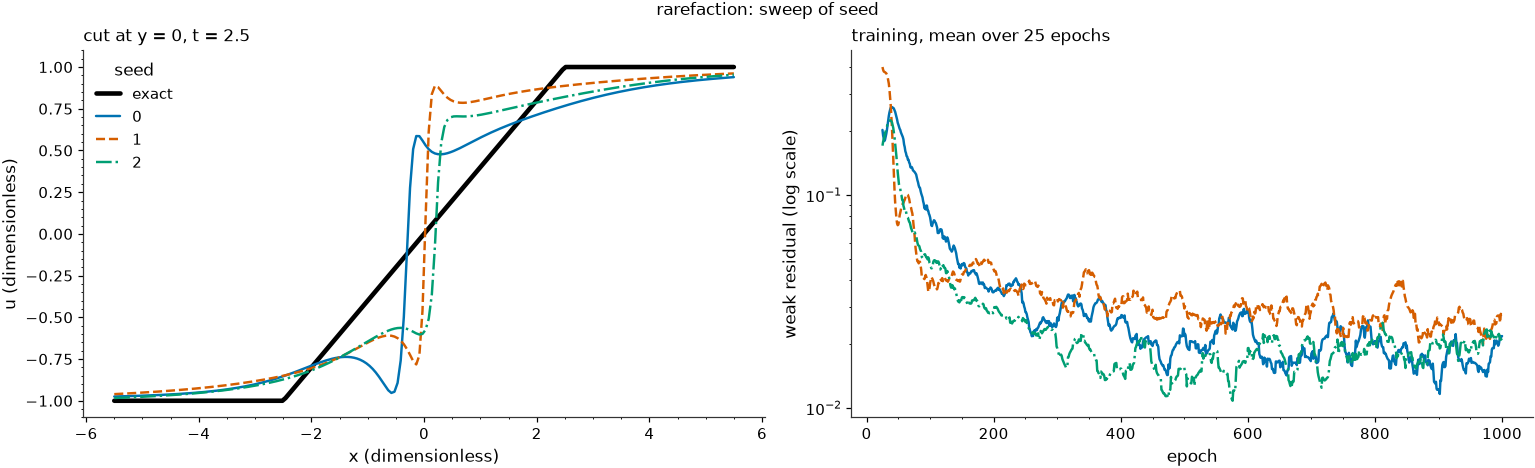

In [34]:
report_parameter_sweep(sweep_runs["seed"], RAREFACTION_PROBLEM, "seed")

## Número de constantes $c$

La desigualdad de Kruzhkov debe valer para **toda** $c$, pero sólo se prueban
`n_kruzhkov_constants` de ellas, repartidas en una rejilla. Con 3 constantes
($-1.5, 0, 1.5$) hay una sola $c$ dentro del rango de $u$: la condición de
entropía se revisa en un único nivel del abanico. Más constantes revisan más
niveles, a costo lineal en memoria.

**Qué esperar:** con pocas $c$, más riesgo de que sobreviva algo del choque de
expansión; entre 9 y 17, poca diferencia.

            n_kruzhkov_constants   rel. L1   rel. L2   final weak  seconds
                               3    0.2033    0.2873    1.733e-02       24
                               9    0.2109    0.2878    1.840e-02       26
                              17    0.2103    0.2885    1.898e-02       24


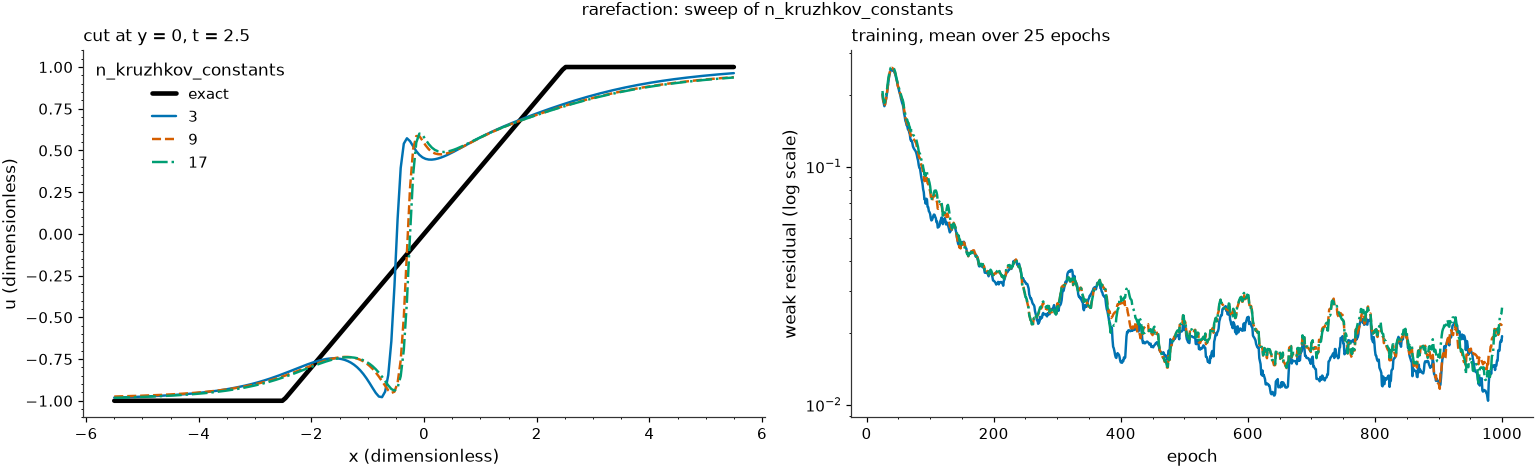

In [35]:
report_parameter_sweep(sweep_runs["n_kruzhkov_constants"], RAREFACTION_PROBLEM, "n_kruzhkov_constants")

## Margen de las constantes fuera del rango de $u$

Con $c < \min u$ el residual de entropía **es** el residual de la ecuación, y
con $c > \max u$ es su negativo: las $c$ de los extremos imponen la EDP; las de
adentro, la desigualdad. Con margen 0 los extremos quedan justo en $\pm 1$,
donde $\operatorname{sign}(u - c)$ empieza a fallar si $u$ toca el borde de su
rango. Con margen 0.5 las $c$ se separan más y quedan menos en el interior.

**Qué esperar:** margen 0 puede imponer peor la ecuación cerca de $u = \pm 1$;
margen grande gasta constantes fuera del rango donde no dicen nada nuevo.

        kruzhkov_margin_fraction   rel. L1   rel. L2   final weak  seconds
                             0.0    0.2197    0.3010    1.123e-02       24
                            0.25    0.2109    0.2878    1.840e-02       26
                             0.5    0.2127    0.2877    1.822e-02       24


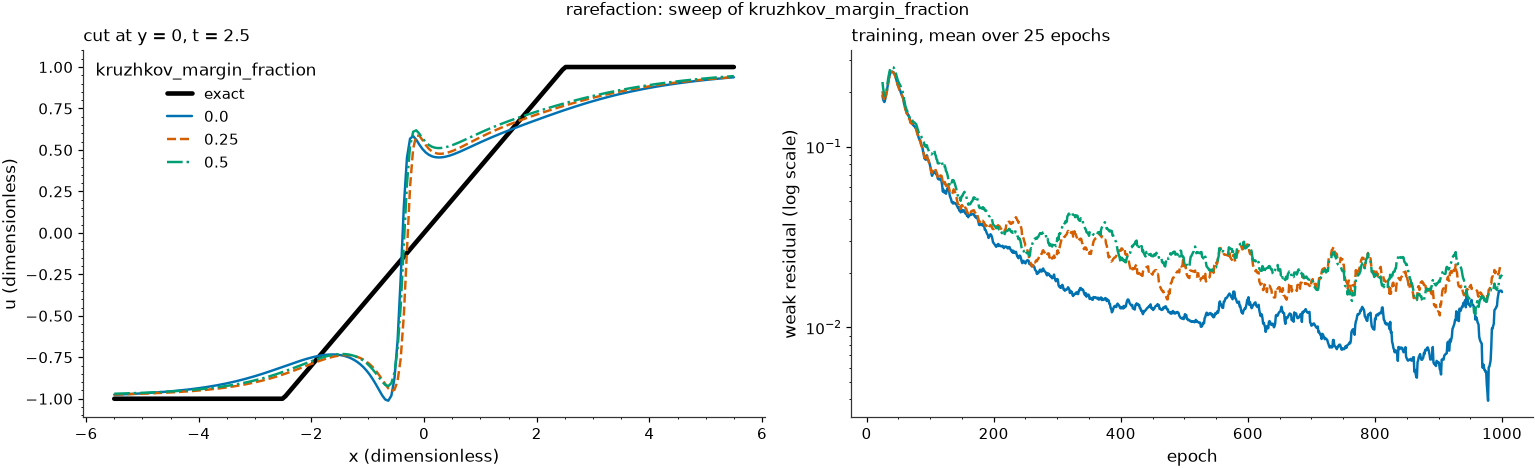

In [36]:
report_parameter_sweep(sweep_runs["kruzhkov_margin_fraction"], RAREFACTION_PROBLEM, "kruzhkov_margin_fraction")

## Agregación sobre $c$: max contra mean

El residual da un número $J(c)$ por cada constante. Para entrenar hace falta
**un** escalar:

- **max** toma la peor $c$, la que más viola la entropía. Una sola $c$ mala
  manda toda la pérdida. Es lo que pide la teoría: la desigualdad vale para
  **toda** $c$.
- **mean** promedia todas. Una $c$ mala se diluye entre las buenas.

**Qué esperar:** en los experimentos 1D, mean dejaba que el choque se
desdibujara. Aquí se ve si en 2D pasa lo mismo.

                aggregation_mode   rel. L1   rel. L2   final weak  seconds
                             max    0.2109    0.2878    1.840e-02       26
                            mean    0.2294    0.3275    1.119e-02       24


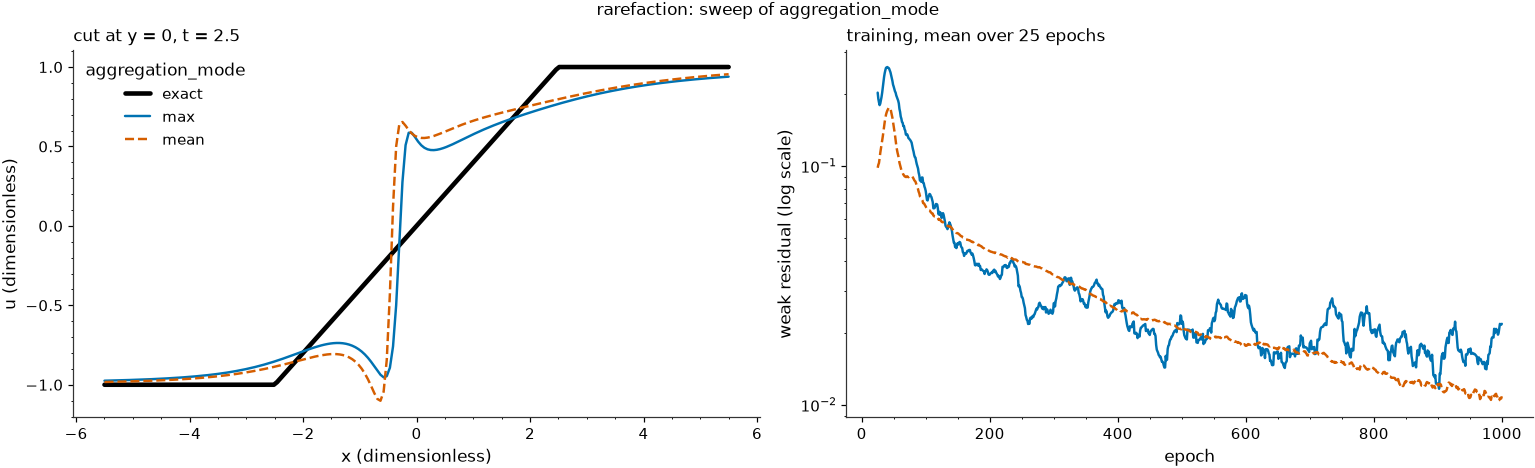

In [37]:
report_parameter_sweep(sweep_runs["aggregation_mode"], RAREFACTION_PROBLEM, "aggregation_mode")

## Pasos de ascenso de la adversaria

Cuántos pasos da $\varphi$ por época buscando la peor violación antes de que
$u$ responda. Con 1 paso $\varphi$ casi no sale de su inicialización aleatoria
(se resortea cada época): el examinador hace preguntas al azar. Con 20 llega
más cerca del máximo, a cambio de ~4 veces más costo de ascenso.

**Qué esperar:** más pasos, residual más exigente y en principio mejor
selección de entropía; el tiempo de corrida crece.

               n_adversary_steps   rel. L1   rel. L2   final weak  seconds
                               1    0.2149    0.2917    1.655e-02       10
                               5    0.2109    0.2878    1.840e-02       26
                              20    0.1595    0.2220    4.468e-02       78


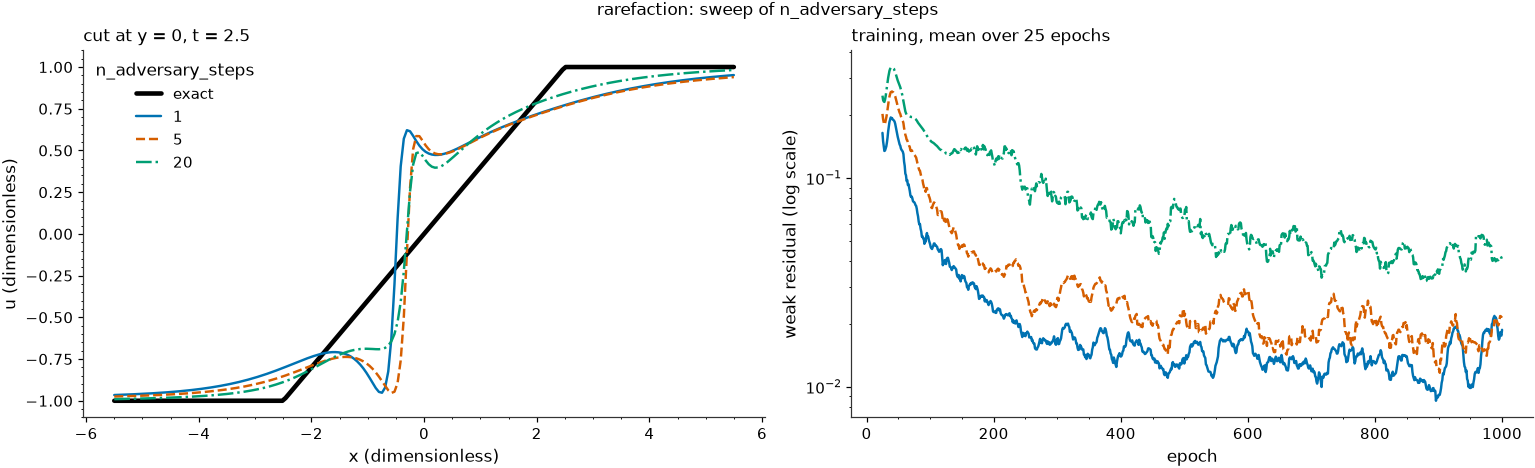

In [38]:
report_parameter_sweep(sweep_runs["n_adversary_steps"], RAREFACTION_PROBLEM, "n_adversary_steps")

## Paso de aprendizaje de la adversaria

Tamaño del paso de Adam sobre $\varphi$. Junto con los pasos de ascenso, fija
cuánto puede alejarse $\varphi$ de su inicialización en una época. Con $10^{-3}$
casi no se mueve; con $10^{-1}$ puede saltar de un lado a otro sin asentarse.

**Qué esperar:** un óptimo en medio; los extremos se parecen a "adversaria débil"
por razones opuestas.

         adversary_learning_rate   rel. L1   rel. L2   final weak  seconds
                           0.001    0.2107    0.2956    1.410e-02       25
                            0.01    0.2109    0.2878    1.840e-02       26
                             0.1    0.1783    0.2437    3.086e-02       24


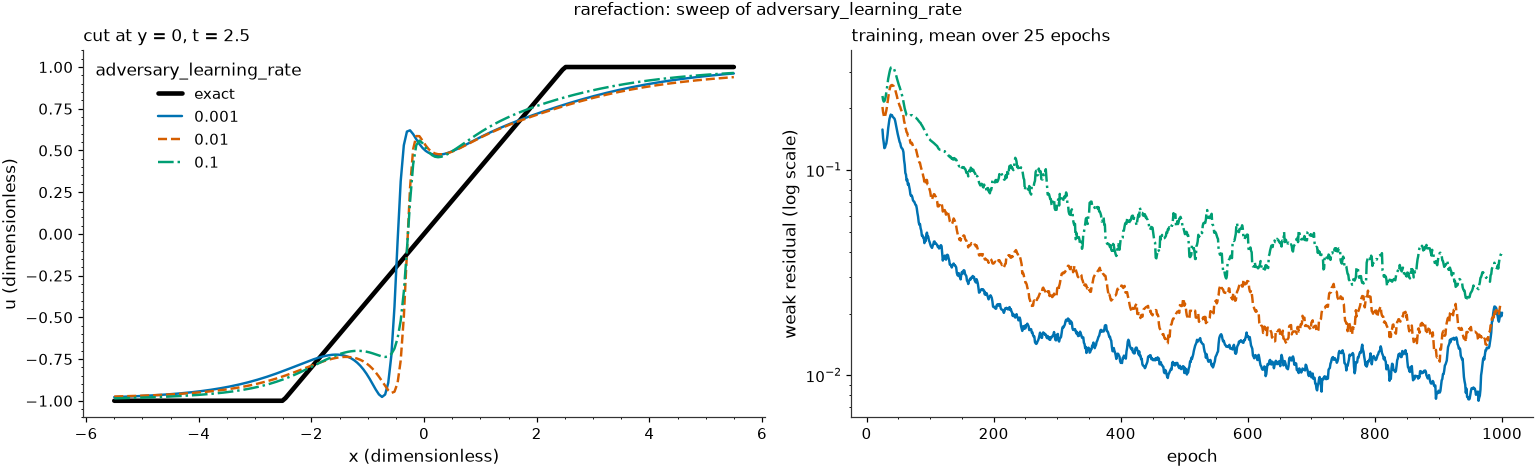

In [39]:
report_parameter_sweep(sweep_runs["adversary_learning_rate"], RAREFACTION_PROBLEM, "adversary_learning_rate")

## Reinicio de la adversaria

Cada cuántas épocas se resortean los pesos de $\varphi$ (y el estado de Adam).
**1** es el algoritmo de De Ryck: $\varphi$ empieza de cero cada época.
**10** la deja acumular durante 10 épocas. **never** nunca la reinicia: $\varphi$
persigue a $u$ durante todo el entrenamiento.

**Qué esperar:** sin reinicio, $\varphi$ puede quedarse defendiendo una
violación vieja que $u$ ya corrigió; o, al revés, acumular un examinador más
fuerte que el que se logra en 5 pasos desde cero.

  reset_adversary_every_n_epochs   rel. L1   rel. L2   final weak  seconds
                               1    0.2109    0.2878    1.840e-02       26
                              10    0.1604    0.2186    6.569e-02       24
                           never    0.3329    0.4970    2.336e-01       24


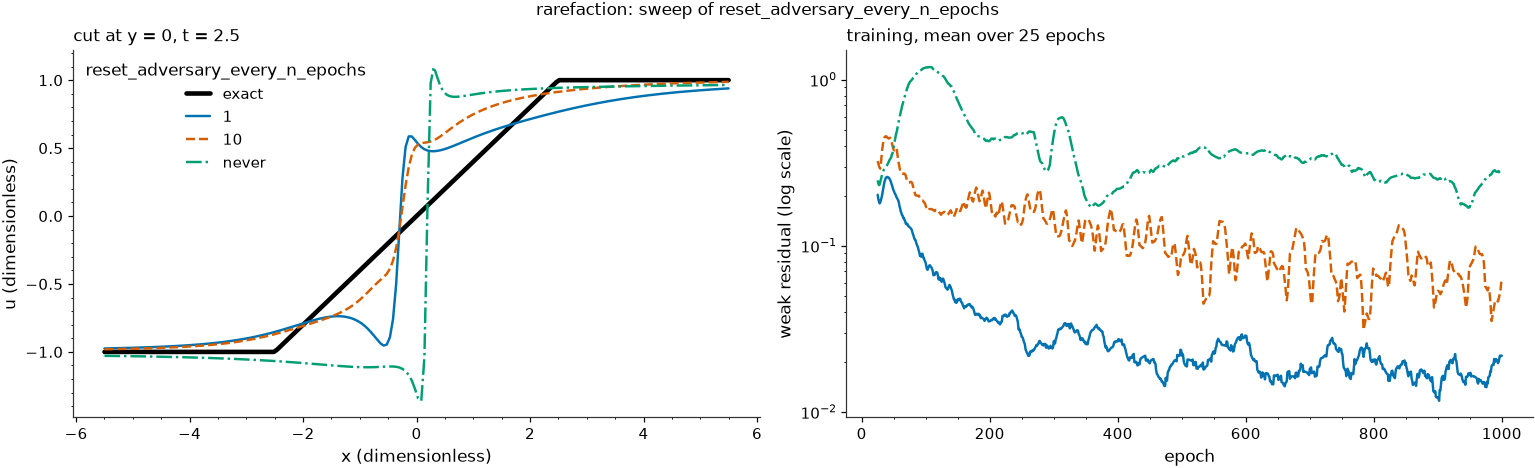

In [40]:
report_parameter_sweep(sweep_runs["reset_adversary_every_n_epochs"], RAREFACTION_PROBLEM, "reset_adversary_every_n_epochs")

## Resumen

Error relativo $L^1$ en $t = T$ de todas las corridas y su cambio respecto del
caso base. Se marcan los cambios mayores que la dispersión entre semillas: ésos
son los que muestran un efecto que no se explica por azar (con sólo tres
semillas, la dispersión es una estimación gruesa).

In [41]:
print_all_sweeps_summary(sweep_runs, BASELINE_SETTINGS)

baseline relative L1 = 0.2109   seed-to-seed spread = 0.0242

parameter                           value   rel. L1    change
n_kruzhkov_constants                    3    0.2033   -0.0077
n_kruzhkov_constants                    9    0.2109   +0.0000
n_kruzhkov_constants                   17    0.2103   -0.0007
kruzhkov_margin_fraction              0.0    0.2197   +0.0088
kruzhkov_margin_fraction             0.25    0.2109   +0.0000
kruzhkov_margin_fraction              0.5    0.2127   +0.0018
aggregation_mode                      max    0.2109   +0.0000
aggregation_mode                     mean    0.2294   +0.0185
n_adversary_steps                       1    0.2149   +0.0039
n_adversary_steps                       5    0.2109   +0.0000
n_adversary_steps                      20    0.1595   -0.0515  <- larger than seed spread
adversary_learning_rate             0.001    0.2107   -0.0002
adversary_learning_rate              0.01    0.2109   +0.0000
adversary_learning_rate               0.1 